# Shift-Separable Reliability Pilot for Time-Series OOD Forecasting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ashhar-Hussain/TS-OOD-Pilot/blob/main/ts_ood_pilot.ipynb)

**Ashhar Hussain** · pilot for a proposed Master's project on OOD evaluation of time-series forecasting ·
CPU only, under a minute including the dataset download · every number below is produced by the code in this notebook

**Question.** Time-series OOD methods are usually evaluated on one shift construction and summarised by one number.
The TS-OOD survey by Wu, Teng *et al.* lists *uncertainty quantification and benchmark OOD evaluation* as an open
challenge and notes that concept shift in time series is under-studied. This notebook asks a small, concrete version of
that question: **does a normalisation method's "OOD gain" survive when shift types are separated?**

**Design** (shift axes and severities fixed before the first run; hyperparameters chosen on validation only — see §7)

| Item | Choice |
|---|---|
| Data | ETTh1, oil temperature (OT), univariate; standard 12/4/4-month split; z-scored with training statistics |
| Task | lookback L = 96 h → horizon H = 24 h, sliding windows (stride 1) |
| Conditions | NATURAL (unmodified test period) + 4 controlled axes × 3 severities applied to the test period |
| LEVEL | mean shift of +0.5 / 1 / 2 training-σ, away from the training mean (moment-1 covariate shift) |
| SCALE | amplitude × 1.5 / 2 / 3 around the test mean (moment-2 covariate shift) |
| PERIOD | time-warp so the daily cycle becomes 21 / 18 / 15 h — the history→future mapping changes (a P(Y∣X) / concept-type shift) |
| NOISE | Gaussian sensor noise σ = 0.1 / 0.2 / 0.4 training-σ on the *inputs only*; targets stay clean (3 noise draws) |
| Methods | seasonal naive; ridge **Linear**; **NLinear** (last-value normalisation); **RevIN-Linear** (instance normalisation, no affine); **MLP** and **RevIN-MLP** (3 seeds each). Ridge strength chosen on validation from 0.1–10⁴ |
| Accuracy inference | Diebold–Mariano test with Harvey–Leybourne–Newbold correction and Newey–West variance (lag H−1); Holm correction across the 13 conditions; moving-block bootstrap 95 % CIs (block = 2H) |
| Uncertainty | split-conformal 90 % intervals calibrated on the validation period; empirical coverage under every shift |

McNemar's test is deliberately **not** used: it is for paired binary outcomes, whereas forecast errors are continuous
and overlapping windows are serially dependent.

In [1]:
import os, json, time, platform, warnings, itertools
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=ConvergenceWarning)
T0 = time.time()

CFG = dict(L=96, H=24, mlp_seeds=[0, 1, 2], noise_seeds=[0, 1, 2], ridge_alphas=[0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0],
           conformal_level=0.90, n_boot=2000, block=48, boot_seed=2027)
SEVERITIES = {"LEVEL": [0.5, 1.0, 2.0], "SCALE": [1.5, 2.0, 3.0], "PERIOD": [21, 18, 15], "NOISE": [0.1, 0.2, 0.4]}
UNITS = {"LEVEL": "σ", "SCALE": "×", "PERIOD": "h", "NOISE": "σ"}
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
L, H = CFG["L"], CFG["H"]
print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1 · Data
ETTh1 is downloaded from the dataset authors' GitHub (Zhou *et al.*, AAAI 2021). If you are offline, put `ETTh1.csv`
next to this notebook.

In [2]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"
try:
    df = pd.read_csv(URL); source = "GitHub (zhouhaoyi/ETDataset)"
except Exception:
    df = pd.read_csv("ETTh1.csv"); source = "local ETTh1.csv"

ot = df["OT"].to_numpy(dtype=float)
n_tr, n_va, n_te = 12 * 30 * 24, 4 * 30 * 24, 4 * 30 * 24          # standard ETT split
mu, sd = ot[:n_tr].mean(), ot[:n_tr].std()
z = (ot - mu) / sd

s_train = z[:n_tr]
s_val = z[n_tr - L: n_tr + n_va]                 # lookback context borrowed from the end of train (standard protocol)
s_test = z[n_tr + n_va - L: n_tr + n_va + n_te]
test_only = z[n_tr + n_va: n_tr + n_va + n_te]
DIRECTION = float(np.sign(test_only.mean() - s_train.mean()) or 1.0)   # LEVEL shifts move further from the training mean

def windows(s):
    W = sliding_window_view(s, L + H)
    return W[:, :L].copy(), W[:, L:].copy()

Xtr, Ytr = windows(s_train)
Xva, Yva = windows(s_val)
print(f"source: {source} | {len(df)} hourly rows | train/val/test hours = {n_tr}/{n_va}/{n_te}")
print(f"windows: train {len(Xtr)}, val {len(Xva)}, test {len(windows(s_test)[0])}")
print(f"mean OT in training-σ units: train {s_train.mean():+.2f}, val {z[n_tr:n_tr+n_va].mean():+.2f}, "
      f"test {test_only.mean():+.2f}  → natural shift already present; LEVEL direction = {DIRECTION:+.0f}")

source: GitHub (zhouhaoyi/ETDataset) | 17420 hourly rows | train/val/test hours = 8640/2880/2880
windows: train 8521, val 2857, test 2857
mean OT in training-σ units: train +0.00, val -0.17, test -1.34  → natural shift already present; LEVEL direction = -1


## 2 · Shift constructions
Each axis changes one property of the test period. PERIOD resamples the clean series so it evolves faster
(24 h cycle → 21/18/15 h); level and amplitude are almost unchanged, but the history→future mapping is not.

In [3]:
def make_condition(axis, sev, seed=None, s=s_test):
    """Return (series used as model input, series used as forecast target)."""
    if axis == "NATURAL":
        return s, s
    if axis == "LEVEL":
        t = s + DIRECTION * sev; return t, t
    if axis == "SCALE":
        m = s.mean(); t = m + sev * (s - m); return t, t
    if axis == "PERIOD":
        r = 24.0 / sev
        t = np.interp(np.arange(0, len(s) - 1 + 1e-9, r), np.arange(len(s)), s); return t, t
    if axis == "NOISE":
        return s + np.random.default_rng(seed).normal(0.0, sev, size=s.shape), s
    raise ValueError(axis)

CONDITIONS = [("NATURAL", None)] + [(a, v) for a in SEVERITIES for v in SEVERITIES[a]]
def label(axis, sev):
    return "natural" if axis == "NATURAL" else f"{axis.lower()} {sev:g}{UNITS[axis]}"

def realisations(axis, sev):
    """Deterministic shifts have one realisation; NOISE is averaged over three noise draws."""
    seeds = CFG["noise_seeds"] if axis == "NOISE" else [None]
    out = []
    for sd_ in seeds:
        si, st = make_condition(axis, sev, sd_)
        Xi, _ = windows(si); _, Yt = windows(st)
        out.append((Xi, Yt))
    return out

## 3 · Forecasters
`NLinear` (Zeng *et al.*, AAAI 2023) subtracts the last observed value; `RevIN-Linear` follows reversible instance
normalisation (Kim *et al.*, ICLR 2022) without the learnable affine. Ridge strength is chosen on the validation period.

In [4]:
EPS = 1e-5

def normalise(X, kind):
    if kind == "none":
        return X, np.zeros((len(X), 1)), np.ones((len(X), 1))
    if kind == "last":
        c = X[:, -1:]; return X - c, c, np.ones_like(c)
    if kind == "revin":
        m = X.mean(1, keepdims=True); s = X.std(1, keepdims=True) + EPS; return (X - m) / s, m, s
    raise ValueError(kind)

class Forecaster:
    def __init__(self, name, head, kind, seed=None):
        self.name, self.head, self.kind, self.seed = name, head, kind, seed

    def _predict_with(self, model, X):
        Xn, c, s = normalise(X, self.kind)
        return model.predict(Xn) * s + c

    def fit(self, X, Y, Xv, Yv):
        Xn, c, s = normalise(X, self.kind)
        Yn = (Y - c) / s
        if self.head == "ridge":
            fits = [(np.mean((self._predict_with(m, Xv) - Yv) ** 2), a, m)
                    for a in CFG["ridge_alphas"] for m in [Ridge(alpha=a).fit(Xn, Yn)]]
            _, self.alpha, self.model = min(fits, key=lambda f: f[0])
        else:
            self.model = MLPRegressor(hidden_layer_sizes=(128,), batch_size=256, learning_rate_init=1e-3,
                                      max_iter=60, early_stopping=True, n_iter_no_change=6,
                                      random_state=self.seed).fit(Xn, Yn)
        return self

    def predict(self, X):
        return self._predict_with(self.model, X)

class SeasonalNaive:
    name = "SNaive"
    def fit(self, *args): return self
    def predict(self, X): return np.tile(X[:, -24:], (1, int(np.ceil(H / 24))))[:, :H]

t_fit = time.time()
MODELS = {"SNaive": [SeasonalNaive()]}
for name, kind in [("Linear", "none"), ("NLinear", "last"), ("RevIN-Linear", "revin")]:
    MODELS[name] = [Forecaster(name, "ridge", kind).fit(Xtr, Ytr, Xva, Yva)]
for name, kind in [("MLP", "none"), ("RevIN-MLP", "revin")]:
    MODELS[name] = [Forecaster(name, "mlp", kind, seed).fit(Xtr, Ytr, Xva, Yva) for seed in CFG["mlp_seeds"]]
METHODS = list(MODELS)
print(f"fitted {sum(len(v) for v in MODELS.values())} models in {time.time() - t_fit:.1f}s; "
      f"ridge alphas: " + ", ".join(f"{m}={MODELS[m][0].alpha:g}" for m in ["Linear", "NLinear", "RevIN-Linear"]))

fitted 10 models in 10.9s; ridge alphas: Linear=10, NLinear=10, RevIN-Linear=1000


## 4 · Evaluation: accuracy, paired tests, and conformal coverage
Split-conformal intervals use validation residuals per horizon step. A second, *σ-scaled* variant divides residuals
by the input window's standard deviation, so interval width follows the local scale.

In [5]:
LEVEL_ADJ = lambda n: min(1.0, np.ceil((n + 1) * CFG["conformal_level"]) / n)
CAL = {}
for m in METHODS:
    CAL[m] = []
    for f in MODELS[m]:
        R = np.abs(f.predict(Xva) - Yva)
        sig = Xva.std(1, keepdims=True) + EPS
        q = LEVEL_ADJ(len(R))
        CAL[m].append((np.quantile(R, q, axis=0), np.quantile(R / sig, q, axis=0)))

def evaluate(axis, sev):
    """Per-window MAE (averaged over seeds and noise draws), MSE, and conformal coverage for every method."""
    reals = realisations(axis, sev)
    res = {}
    for m in METHODS:
        maes, mses, cov_std, cov_scaled, wid_std, wid_scaled, by_seed = [], [], [], [], [], [], []
        for f, (q_std, q_sc) in zip(MODELS[m], CAL[m]):
            seed_maes = []
            for Xi, Yt in reals:
                P = f.predict(Xi); E = np.abs(P - Yt)
                sig = Xi.std(1, keepdims=True) + EPS
                maes.append(E.mean(1)); mses.append((E ** 2).mean()); seed_maes.append(E.mean())
                cov_std.append((E <= q_std).mean()); wid_std.append(2 * q_std.mean())
                cov_scaled.append((E <= q_sc * sig).mean()); wid_scaled.append(2 * (q_sc * sig).mean())
            by_seed.append(float(np.mean(seed_maes)))
        res[m] = dict(window_mae=np.mean(maes, 0), mae=float(np.mean(maes)), mse=float(np.mean(mses)), mae_by_seed=by_seed,
                      cov_std=float(np.mean(cov_std)), cov_scaled=float(np.mean(cov_scaled)),
                      width_std=float(np.mean(wid_std)), width_scaled=float(np.mean(wid_scaled)))
    Xi0 = reals[0][0]
    res["_shift_score"] = float(stats.wasserstein_distance(Xtr.mean(1), Xi0.mean(1)) / Xtr.mean(1).std()
                                + stats.wasserstein_distance(np.log(Xtr.std(1) + EPS), np.log(Xi0.std(1) + EPS))
                                / np.log(Xtr.std(1) + EPS).std())
    res["_n_windows"] = len(Xi0)
    return res

def dm_hln(d, h):
    """Two-sided Diebold–Mariano test, HLN small-sample correction, Newey–West (Bartlett) variance with lag h-1."""
    d = np.asarray(d, float); T = len(d); dc = d - d.mean()
    lrv = dc @ dc / T + sum(2 * (1 - k / h) * (dc[k:] @ dc[:-k]) / T for k in range(1, h))
    stat = d.mean() / np.sqrt(lrv / T) * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return float(stat), float(2 * stats.t.sf(abs(stat), df=T - 1))

def block_bootstrap_gain(e_base, e_method, block, n_boot, rng):
    """Paired moving-block bootstrap 95 % CI for the relative MAE gain 1 - MAE_method / MAE_base."""
    T = len(e_base); nb = int(np.ceil(T / block))
    starts = rng.integers(0, T - block + 1, size=(n_boot, nb))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :T]
    g = 1 - e_method[idx].mean(1) / e_base[idx].mean(1)
    return np.percentile(g, [2.5, 97.5])

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); running = 0.0
    for i, j in enumerate(order):
        running = max(running, (len(p) - i) * p[j]); adj[j] = min(1.0, running)
    return adj

t_eval = time.time()
RESULTS = {(a, v): evaluate(a, v) for a, v in CONDITIONS}
print(f"evaluated {len(CONDITIONS)} conditions × {len(METHODS)} methods in {time.time() - t_eval:.1f}s")

evaluated 13 conditions × 6 methods in 1.0s


## 5 · Results — accuracy under each shift
Relative gain = 1 − MAE(method) / MAE(baseline): positive means the OOD-motivated method helps.

In [6]:
PAIRS = [("NLinear", "Linear"), ("RevIN-Linear", "Linear"), ("RevIN-MLP", "MLP")]
rng = np.random.default_rng(CFG["boot_seed"])
rows = []
for a, v in CONDITIONS:
    R = RESULTS[(a, v)]
    row = dict(condition=label(a, v), axis=a, severity=v, windows=R["_n_windows"], shift_score=R["_shift_score"])
    for m in METHODS:
        row[f"MAE {m}"] = R[m]["mae"]; row[f"MSE {m}"] = R[m]["mse"]
    for m, b in PAIRS:
        eb, em = R[b]["window_mae"], R[m]["window_mae"]
        lo, hi = block_bootstrap_gain(eb, em, CFG["block"], CFG["n_boot"], rng)
        lo2, hi2 = block_bootstrap_gain(eb, em, 2 * CFG["block"], CFG["n_boot"], rng)   # robustness: block = 4H
        stat, p = dm_hln(eb - em, H)
        row.update({f"gain {m}": 1 - em.mean() / eb.mean(), f"lo {m}": lo, f"hi {m}": hi,
                    f"lo4H {m}": lo2, f"hi4H {m}": hi2, f"DM {m}": stat, f"p {m}": p})
    for m in METHODS:
        row[f"cov {m}"] = R[m]["cov_std"]; row[f"covS {m}"] = R[m]["cov_scaled"]
        row[f"width {m}"] = R[m]["width_std"]; row[f"widthS {m}"] = R[m]["width_scaled"]
    rows.append(row)
table = pd.DataFrame(rows)
for m, _ in PAIRS:
    table[f"p_holm {m}"] = holm(table[f"p {m}"].to_numpy())

def pct(x): return f"{100 * x:+.1f}%"
show = pd.DataFrame({"condition": table["condition"]})
for m in METHODS:
    show[m] = table[f"MAE {m}"].map(lambda x: f"{x:.3f}")
for m, b in PAIRS:
    show[f"{m} vs {b}"] = [f"{pct(g)} [{pct(lo)}, {pct(hi)}]{'*' if ph < 0.05 else ''}"
                           for g, lo, hi, ph in zip(table[f"gain {m}"], table[f"lo {m}"], table[f"hi {m}"], table[f"p_holm {m}"])]
print("MAE (z-units) and relative gain with 95% block-bootstrap CI; * = Holm-adjusted DM p < 0.05")
print(show.to_string(index=False))

# robustness of the CI to block length
flips = sum(int((table[f"lo {m}"].iloc[i] > 0) != (table[f"lo4H {m}"].iloc[i] > 0) or
                (table[f"hi {m}"].iloc[i] < 0) != (table[f"hi4H {m}"].iloc[i] < 0))
            for m, _ in PAIRS for i in range(len(table)))
print(f"\nCI sign conclusions that change when the bootstrap block grows from 2H to 4H: {flips} of {3 * len(table)}")

# multi-seed check: is the MLP effect larger than seed-to-seed variation?
seed_gain = {label(a, v): [1 - r / b for r, b in zip(RESULTS[(a, v)]["RevIN-MLP"]["mae_by_seed"], RESULTS[(a, v)]["MLP"]["mae_by_seed"])]
             for a, v in CONDITIONS}
table["seed_min RevIN-MLP"] = [min(seed_gain[c]) for c in table.condition]
table["seed_max RevIN-MLP"] = [max(seed_gain[c]) for c in table.condition]
print("RevIN-MLP vs MLP, per-seed gain range (3 paired seeds): " +
      "; ".join(f"{c} {pct(min(v))}…{pct(max(v))}" for c, v in seed_gain.items()))

MAE (z-units) and relative gain with 95% block-bootstrap CI; * = Holm-adjusted DM p < 0.05
 condition SNaive Linear NLinear RevIN-Linear   MLP RevIN-MLP       NLinear vs Linear   RevIN-Linear vs Linear         RevIN-MLP vs MLP
   natural  0.166  0.124   0.123        0.124 0.143     0.131    +0.5% [-2.3%, +2.9%]     +0.0% [-3.0%, +2.6%]   +8.2% [+3.8%, +12.7%]*
level 0.5σ  0.166  0.126   0.123        0.124 0.184     0.131    +2.2% [-1.3%, +5.2%]     +1.7% [-2.0%, +4.9%] +28.7% [+23.9%, +33.1%]*
  level 1σ  0.166  0.129   0.123        0.124 0.240     0.131    +4.4% [+0.3%, +8.1%]     +3.9% [-0.3%, +7.8%] +45.2% [+41.6%, +48.7%]*
  level 2σ  0.166  0.138   0.123        0.124 0.370     0.131 +10.2% [+5.3%, +14.3%]*   +9.8% [+4.6%, +14.3%]* +64.4% [+62.3%, +66.6%]*
scale 1.5×  0.249  0.185   0.185        0.186 0.200     0.197    -0.3% [-2.2%, +1.4%]     -0.9% [-3.1%, +1.3%]     +1.6% [-2.9%, +6.0%]
  scale 2×  0.333  0.245   0.247        0.248 0.261     0.263    -0.6% [-2.2%, +0.8%]     -1.

## 6 · Does the headline number depend on the benchmark's shift mix?
Take the medium severity of each axis. Any benchmark built from a non-empty subset of the four axes reports the mean
gain over its axes. If the range crosses zero, the sign of the headline result is a property of the benchmark.

In [7]:
MEDIUM = {a: SEVERITIES[a][1] for a in SEVERITIES}
AXES = list(SEVERITIES)
subset_stats = {}
for m, b in PAIRS:
    g_axis = {a: float(table.loc[(table.axis == a) & (table.severity == MEDIUM[a]), f"gain {m}"].iloc[0]) for a in AXES}
    subs = [c for k in range(1, 5) for c in itertools.combinations(AXES, k)]
    vals = {"+".join(c): float(np.mean([g_axis[a] for a in c])) for c in subs}
    natural = float(table.loc[table.axis == "NATURAL", f"gain {m}"].iloc[0])
    lo_key, hi_key = min(vals, key=vals.get), max(vals, key=vals.get)
    subset_stats[f"{m} vs {b}"] = dict(per_axis=g_axis, subsets=vals, natural=natural,
                                       min=(lo_key, vals[lo_key]), max=(hi_key, vals[hi_key]))
    print(f"{m} vs {b}: natural {pct(natural)} | per axis " + ", ".join(f"{a.lower()} {pct(g)}" for a, g in g_axis.items())
          + f" | subset range {pct(vals[lo_key])} ({lo_key.lower()}) … {pct(vals[hi_key])} ({hi_key.lower()})")

ranks = {}
for a in ["NATURAL"] + AXES:
    v = None if a == "NATURAL" else MEDIUM[a]
    r = table.loc[(table.axis == a) & ((table.severity == v) if v is not None else True)].iloc[0]
    ranks[label(a, v)] = sorted(METHODS, key=lambda m: r[f"MAE {m}"])
print("\nmethod ranking by MAE (best → worst), medium severity:")
for k, v in ranks.items():
    print(f"  {k:<14} " + " > ".join(v))

NLinear vs Linear: natural +0.5% | per axis level +4.4%, scale -0.6%, period +0.6%, noise -2.9% | subset range -2.9% (noise) … +4.4% (level)
RevIN-Linear vs Linear: natural +0.0% | per axis level +3.9%, scale -1.1%, period -0.2%, noise +6.8% | subset range -1.1% (scale) … +6.8% (noise)
RevIN-MLP vs MLP: natural +8.2% | per axis level +45.2%, scale -0.6%, period -0.8%, noise -1.9% | subset range -1.9% (noise) … +45.2% (level)

method ranking by MAE (best → worst), medium severity:
  natural        NLinear > RevIN-Linear > Linear > RevIN-MLP > MLP > SNaive
  level 1σ       NLinear > RevIN-Linear > Linear > RevIN-MLP > SNaive > MLP
  scale 2×       Linear > NLinear > RevIN-Linear > MLP > RevIN-MLP > SNaive
  period 18h     NLinear > Linear > RevIN-Linear > MLP > RevIN-MLP > SNaive
  noise 0.2σ     RevIN-Linear > Linear > NLinear > MLP > RevIN-MLP > SNaive


## 7 · Underspecification check: can in-distribution validation pick the OOD winner?
Ridge strength is chosen on the validation period, which is (nearly) in-distribution. During development the grid
stopped at 100, where RevIN-Linear's choice sat on the boundary; extending the grid changed its sensor-noise result
from a loss to a gain. Rather than hide that, this cell refits every grid value and scores it on validation and under
the strongest noise shift.

In [8]:
noise_sev = SEVERITIES["NOISE"][-1]
noise_reals = realisations("NOISE", noise_sev)
sweep = []
for name, kind in [("Linear", "none"), ("RevIN-Linear", "revin")]:
    f = Forecaster(name, "ridge", kind)
    Xn, c, s = normalise(Xtr, kind)
    for a in CFG["ridge_alphas"]:
        mdl = Ridge(alpha=a).fit(Xn, (Ytr - c) / s)
        sweep.append(dict(method=name, alpha=a,
                          val_mse=float(np.mean((f._predict_with(mdl, Xva) - Yva) ** 2)),
                          noise_mae=float(np.mean([np.abs(f._predict_with(mdl, Xi) - Yt).mean() for Xi, Yt in noise_reals]))))
sweep = pd.DataFrame(sweep)
sweep["within 1% of best val MSE"] = sweep.groupby("method").val_mse.transform(lambda v: v <= 1.01 * v.min())
print(sweep.to_string(index=False, formatters={"val_mse": "{:.4f}".format, "noise_mae": "{:.3f}".format}))
eq = sweep[sweep["within 1% of best val MSE"]]
eq_lin, eq_rev = eq[eq.method == "Linear"], eq[eq.method == "RevIN-Linear"]
pair_gains = np.array([1 - r / l for r in eq_rev.noise_mae for l in eq_lin.noise_mae])   # every validation-equivalent pairing
UNDERSPEC = dict(severity=noise_sev, n_linear=int(len(eq_lin)), n_revin=int(len(eq_rev)),
                 gain_min=float(pair_gains.min()), gain_max=float(pair_gains.max()),
                 linear_noise_mae=[float(eq_lin.noise_mae.min()), float(eq_lin.noise_mae.max())],
                 revin_noise_mae=[float(eq_rev.noise_mae.min()), float(eq_rev.noise_mae.max())])
print(f"\nValidation-equivalent ridge strengths ({len(eq_lin)} for Linear, {len(eq_rev)} for RevIN-Linear) give RevIN-Linear "
      f"a gain over Linear under noise {noise_sev:g}σ anywhere from {pct(UNDERSPEC['gain_min'])} to {pct(UNDERSPEC['gain_max'])}: "
      f"in-distribution validation does not determine the sign of this OOD comparison.")

      method   alpha val_mse noise_mae  within 1% of best val MSE
      Linear     0.1  0.0512     0.258                       True
      Linear     1.0  0.0512     0.257                       True
      Linear    10.0  0.0511     0.245                       True
      Linear   100.0  0.0512     0.203                       True
      Linear  1000.0  0.0538     0.165                      False
      Linear 10000.0  0.0654     0.157                      False
RevIN-Linear     0.1  0.0522     0.268                       True
RevIN-Linear     1.0  0.0522     0.268                       True
RevIN-Linear    10.0  0.0521     0.267                       True
RevIN-Linear   100.0  0.0520     0.257                       True
RevIN-Linear  1000.0  0.0519     0.215                       True
RevIN-Linear 10000.0  0.0539     0.170                      False

Validation-equivalent ridge strengths (4 for Linear, 5 for RevIN-Linear) give RevIN-Linear a gain over Linear under noise 0.4σ anywhere from 

## 8 · Uncertainty under shift
Empirical coverage of nominal 90 % split-conformal intervals. A point-forecast winner can still give unreliable
uncertainty; a moment-based drift score can also miss the shift that matters.

In [9]:
cov = pd.DataFrame({"condition": table["condition"], "shift score": table["shift_score"].map(lambda x: f"{x:.2f}")})
for m in ["Linear", "RevIN-Linear", "RevIN-MLP"]:
    cov[f"{m} std"] = table[f"cov {m}"].map(lambda x: f"{100*x:.0f}%")
    cov[f"{m} σ-scaled"] = table[f"covS {m}"].map(lambda x: f"{100*x:.0f}%")
print("Coverage of nominal 90% intervals (std = standard split conformal; σ-scaled = residuals scaled by window σ)")
print(cov.to_string(index=False))
nat = table.iloc[0]
print(f"\nmean interval width on natural test (z-units): RevIN-Linear std {nat['width RevIN-Linear']:.2f}, "
      f"σ-scaled {nat['widthS RevIN-Linear']:.2f}")

Coverage of nominal 90% intervals (std = standard split conformal; σ-scaled = residuals scaled by window σ)
 condition shift score Linear std Linear σ-scaled RevIN-Linear std RevIN-Linear σ-scaled RevIN-MLP std RevIN-MLP σ-scaled
   natural        3.19        97%             88%              97%                   89%           98%                89%
level 0.5σ        3.71        96%             88%              97%                   89%           98%                89%
  level 1σ        4.24        96%             87%              97%                   89%           98%                89%
  level 2σ        5.28        94%             86%              97%                   89%           98%                89%
scale 1.5×        1.93        87%             89%              87%                   89%           88%                89%
  scale 2×        1.75        76%             89%              75%                   89%           77%                89%
  scale 3×        3.00        58%     

## 9 · Figures

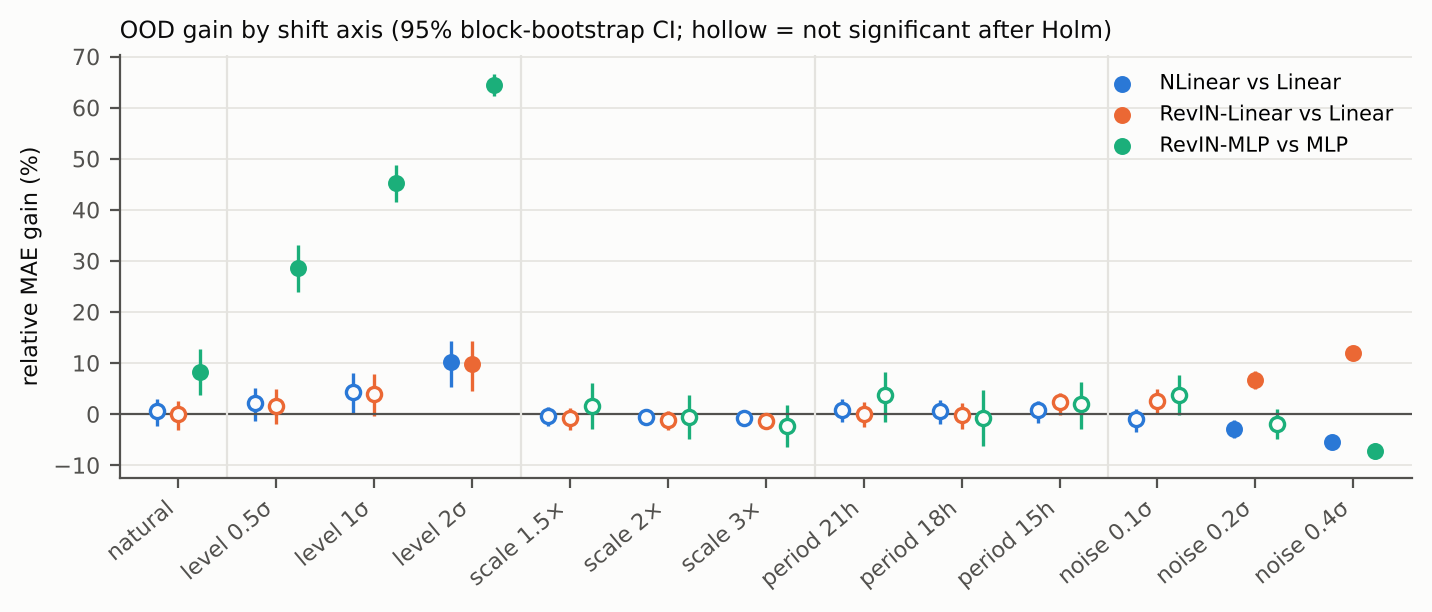

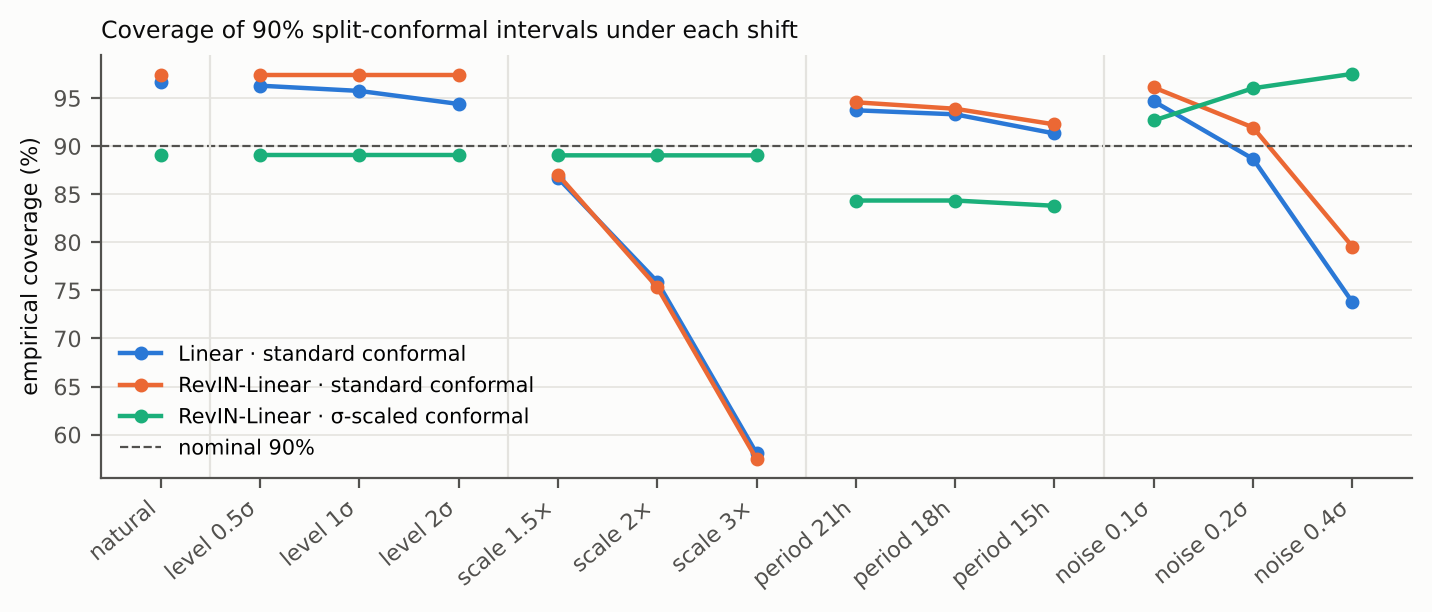

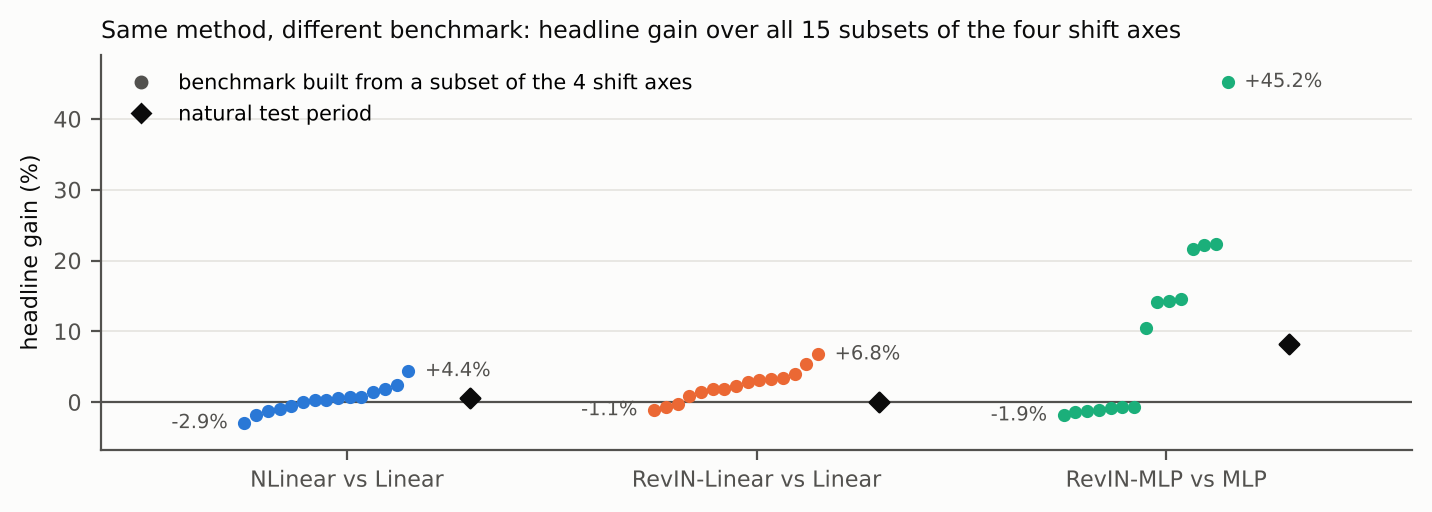

In [10]:
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # validated categorical slots 1-3
plt.rcParams.update({"font.size": 8, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "legend.frameon": False, "font.family": "DejaVu Sans"})
xlabels = [label(a, v) for a, v in CONDITIONS]
x = np.arange(len(CONDITIONS))
group_edges = [0.5, 3.5, 6.5, 9.5]

def style_axis(ax):
    ax.grid(axis="y", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    for e in group_edges: ax.axvline(e, color=GRID, linewidth=0.8)
    ax.set_xticks(x); ax.set_xticklabels(xlabels, rotation=40, ha="right")
    ax.set_xlim(-0.6, len(x) - 0.4)

def plot_gains(ax):
    for k, ((m, b), c) in enumerate(zip(PAIRS, SERIES)):
        off = (k - 1) * 0.22
        g = 100 * table[f"gain {m}"].to_numpy()
        lo = 100 * table[f"lo {m}"].to_numpy(); hi = 100 * table[f"hi {m}"].to_numpy()
        sig = table[f"p_holm {m}"].to_numpy() < 0.05
        ax.errorbar(x + off, g, yerr=[g - lo, hi - g], fmt="none", ecolor=c, elinewidth=1.2, capsize=0)
        ax.scatter(x[sig] + off, g[sig], s=26, color=c, zorder=3, label=f"{m} vs {b}")
        ax.scatter(x[~sig] + off, g[~sig], s=26, facecolor=SURFACE, edgecolor=c, linewidth=1.2, zorder=3)
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_ylabel("relative MAE gain (%)")
    ax.set_title("OOD gain by shift axis (95% block-bootstrap CI; hollow = not significant after Holm)",
                 loc="left", color=INK, fontsize=8.5)
    style_axis(ax); ax.legend(loc="upper right", ncol=1, fontsize=7.5)

GROUPS = [[0], [1, 2, 3], [4, 5, 6], [7, 8, 9], [10, 11, 12]]   # natural | level | scale | period | noise

def plot_coverage(ax):
    spec = [("Linear", "cov", "Linear · standard conformal"),
            ("RevIN-Linear", "cov", "RevIN-Linear · standard conformal"),
            ("RevIN-Linear", "covS", "RevIN-Linear · σ-scaled conformal")]
    for (m, key, lab), c in zip(spec, SERIES):
        yv = 100 * table[f"{key} {m}"].to_numpy()
        for gi, grp in enumerate(GROUPS):            # lines only within an axis: conditions are categorical
            ax.plot(x[grp], yv[grp], color=c, linewidth=1.6, marker="o", markersize=4, label=lab if gi == 0 else None)
    ax.axhline(90, color=INK2, linewidth=0.8, linestyle="--", label="nominal 90%")
    ax.set_ylabel("empirical coverage (%)")
    ax.set_title("Coverage of 90% split-conformal intervals under each shift", loc="left", color=INK, fontsize=8.5)
    style_axis(ax); ax.legend(loc="lower left", fontsize=7.5)

def plot_subsets(ax):
    from matplotlib.lines import Line2D
    for k, ((key, st), c) in enumerate(zip(subset_stats.items(), SERIES)):
        vals = np.sort(100 * np.array(list(st["subsets"].values())))
        xs = k - 0.25 + np.linspace(0, 0.4, len(vals))
        ax.scatter(xs, vals, s=14, color=c, zorder=3)
        ax.annotate(f"{vals.min():+.1f}%", (xs[0], vals.min()), xytext=(-6, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=7, color=INK2)
        ax.annotate(f"{vals.max():+.1f}%", (xs[-1], vals.max()), xytext=(6, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=7, color=INK2)
        ax.scatter([k + 0.3], [100 * st["natural"]], marker="D", s=24, color=INK, zorder=3)
    lo = min(100 * min(st["subsets"].values()) for st in subset_stats.values())
    hi = max(100 * max(st["subsets"].values()) for st in subset_stats.values())
    ax.set_ylim(lo - 0.08 * (hi - lo), hi + 0.08 * (hi - lo))
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="none", color=INK2, markersize=4,
                              label="benchmark built from a subset of the 4 shift axes"),
                       Line2D([], [], marker="D", linestyle="none", color=INK, markersize=4.5, label="natural test period")],
              loc="upper left", fontsize=7.5)
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_xticks(range(len(subset_stats))); ax.set_xticklabels(list(subset_stats)); ax.set_xlim(-0.6, len(subset_stats) - 0.4)
    ax.set_ylabel("headline gain (%)"); ax.grid(axis="y", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    ax.set_title("Same method, different benchmark: headline gain over all 15 subsets of the four shift axes",
                 loc="left", color=INK, fontsize=8.5)

fig, ax = plt.subplots(figsize=(7.2, 3.1)); plot_gains(ax); fig.tight_layout()
fig.savefig(f"{OUT}/fig1_gain_by_axis.png", dpi=200); plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.1)); plot_coverage(ax); fig.tight_layout()
fig.savefig(f"{OUT}/fig2_coverage_under_shift.png", dpi=200); plt.show()
fig, ax = plt.subplots(figsize=(7.2, 2.6)); plot_subsets(ax); fig.tight_layout()
fig.savefig(f"{OUT}/fig3_benchmark_mix.png", dpi=200); plt.show()

fig, axes = plt.subplots(2, 1, figsize=(6.3, 5.5)); plot_gains(axes[0]); plot_coverage(axes[1]); fig.tight_layout()
fig.savefig(f"{OUT}/fig_pilot_summary.pdf"); fig.savefig(f"{OUT}/fig_pilot_summary.png", dpi=200); plt.close(fig)

## 10 · Key findings (generated from the numbers above) and saved outputs

In [11]:
summary = dict(
    config=CFG, severities=SEVERITIES, medium=MEDIUM, n_test_windows=int(table.windows.iloc[0]),
    mae={label(a, v): {m: RESULTS[(a, v)][m]["mae"] for m in METHODS} for a, v in CONDITIONS},
    gains={f"{m} vs {b}": {c: dict(gain=table.loc[i, f"gain {m}"], ci=[table.loc[i, f"lo {m}"], table.loc[i, f"hi {m}"]],
                                   dm=table.loc[i, f"DM {m}"], p_holm=table.loc[i, f"p_holm {m}"])
                           for i, c in enumerate(table.condition)} for m, b in PAIRS},
    coverage={c: {m: dict(standard=table.loc[i, f"cov {m}"], scaled=table.loc[i, f"covS {m}"]) for m in METHODS}
              for i, c in enumerate(table.condition)},
    shift_score=dict(zip(table.condition, table.shift_score)),
    subsets=subset_stats, ranking_medium=ranks)
table.to_csv(f"{OUT}/results_table.csv", index=False)

lines = []
for m, b in PAIRS:
    st = subset_stats[f"{m} vs {b}"]
    per = st["per_axis"]
    lines.append(f"- {m} vs {b}: natural {pct(st['natural'])}; level {pct(per['LEVEL'])}, scale {pct(per['SCALE'])}, "
                 f"period {pct(per['PERIOD'])}, noise {pct(per['NOISE'])} (medium severity). Headline over axis subsets "
                 f"ranges {pct(st['min'][1])} to {pct(st['max'][1])}.")
cov_rows = table.set_index("condition")
worst_std = cov_rows["cov RevIN-Linear"].idxmin(); worst_sc = cov_rows["covS RevIN-Linear"].idxmin()
lines.append(f"- 90% conformal coverage, RevIN-Linear: natural {100*cov_rows['cov RevIN-Linear'].iloc[0]:.0f}%; "
             f"worst {100*cov_rows['cov RevIN-Linear'].min():.0f}% ({worst_std}) with standard intervals, "
             f"worst {100*cov_rows['covS RevIN-Linear'].min():.0f}% ({worst_sc}) with σ-scaled intervals.")
nat_score, nat_mae = table.shift_score.iloc[0], table["MAE Linear"].iloc[0]
quiet = table[(table.axis == "NOISE") & (table.shift_score < nat_score)]
if len(quiet):
    r = quiet.loc[(quiet["MAE Linear"] / nat_mae).idxmax()]
    lines.append(f"- A moment-based drift score is lower for {r.condition} ({r.shift_score:.2f}) than for the unmodified "
                 f"test period ({nat_score:.2f}), yet Linear's MAE is {100 * (r['MAE Linear'] / nat_mae - 1):.0f}% higher.")
lines.append(f"- Underspecification: pairing ridge strengths that are within 1% of each method's best validation MSE, "
             f"RevIN-Linear's gain over Linear under noise {UNDERSPEC['severity']:g}σ ranges from {pct(UNDERSPEC['gain_min'])} "
             f"to {pct(UNDERSPEC['gain_max'])}.")
summary["underspecification"] = UNDERSPEC
summary["findings"] = lines
summary["runtime_seconds"] = round(time.time() - T0, 1)
with open(f"{OUT}/summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\n".join(lines))
print(f"\nSaved: {sorted(os.listdir(OUT))}")
print(f"Total runtime: {summary['runtime_seconds']} s")

- NLinear vs Linear: natural +0.5%; level +4.4%, scale -0.6%, period +0.6%, noise -2.9% (medium severity). Headline over axis subsets ranges -2.9% to +4.4%.
- RevIN-Linear vs Linear: natural +0.0%; level +3.9%, scale -1.1%, period -0.2%, noise +6.8% (medium severity). Headline over axis subsets ranges -1.1% to +6.8%.
- RevIN-MLP vs MLP: natural +8.2%; level +45.2%, scale -0.6%, period -0.8%, noise -1.9% (medium severity). Headline over axis subsets ranges -1.9% to +45.2%.
- 90% conformal coverage, RevIN-Linear: natural 97%; worst 57% (scale 3×) with standard intervals, worst 84% (period 15h) with σ-scaled intervals.
- A moment-based drift score is lower for noise 0.4σ (2.83) than for the unmodified test period (3.19), yet Linear's MAE is 97% higher.
- Underspecification: pairing ridge strengths that are within 1% of each method's best validation MSE, RevIN-Linear's gain over Linear under noise 0.4σ ranges from -32.0% to +16.6%.

Saved: ['fig1_gain_by_axis.png', 'fig2_coverage_under_shi